# Lab: CNN Age Prediction

## Import

In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
import os
import glob 
from sklearn.model_selection import train_test_split

from keras.callbacks import EarlyStopping
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten
from keras.utils import to_categorical
import matplotlib.pyplot as plt
from keras.losses import CategoricalCrossentropy



from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


## Read

In [2]:
image_paths = glob.glob('UTKFace/*.jpg')
paths=[]
ages=[]
genders=[]

for path in image_paths:
    labels = os.path.basename(path).split('_')

    if labels[0].isdigit() and labels[1].isdigit():
        paths.append(path)
        ages.append(int(labels[0]))
        genders.append(int(labels[1]))


In [3]:
#create dataframe
df= pd.DataFrame({
    'path': paths,
    'age': ages,
    'gender': genders
})
df.head()

,path,age,gender
0,UTKFace\100_0_0_20170112213500903.jpg.chip.jpg,100,0
1,UTKFace\100_0_0_20170112215240346.jpg.chip.jpg,100,0
2,UTKFace\100_1_0_20170110183726390.jpg.chip.jpg,100,1
3,UTKFace\100_1_0_20170112213001988.jpg.chip.jpg,100,1
4,UTKFace\100_1_0_20170112213303693.jpg.chip.jpg,100,1


## Inspect Data

In [4]:
df.describe() #age between 1-116

,age,gender
count,23708.000000,23708.000000
mean,33.303484,0.477349
std,19.886112,0.499497
min,1.000000,0.000000
25%,23.000000,0.000000
50%,29.000000,0.000000
75%,45.000000,1.000000
max,116.000000,1.000000


In [5]:
# Gender destirbution
df['gender'].value_counts() 
#mostly balanced but there is more images for males than females

gender
0    12391
1    11317
Name: count, dtype: int64

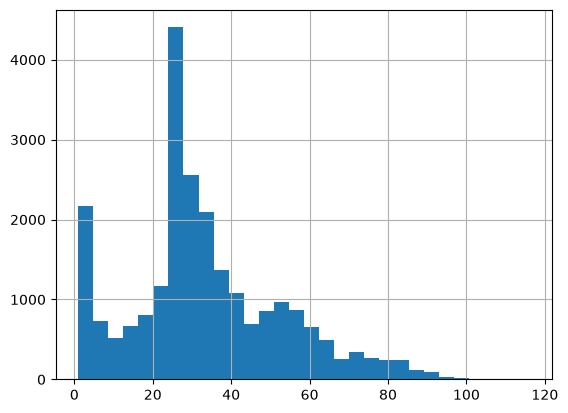

In [53]:
# Age destirbution
df['age'].hist(bins=30);
# data is imbalanced due to having more images for people aged 20-40
#less data for elderies

## Split Data

In [12]:
X=df['path']
y= df[['age','gender']] 
X_train, X_test,y_train, y_test= train_test_split(X,y,test_size=0.2,random_state=42)

In [16]:
#shape of X
print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)


(18966, 64, 64, 3)
(4742, 64, 64, 3)
(18966, 2)
(4742, 2)


## Normalize and load images

In [14]:
from tensorflow.keras.utils import load_img, img_to_array
def load_images(paths):
    images = []
    for path in paths:
        img = load_img(path, target_size=(64, 64))
        img = img_to_array(img)
        images.append(img)

    return np.array(images) / 255.0

In [15]:
X_train= load_images(X_train)
X_test=load_images(X_test)

# Age Prediction Baseline Model

In [29]:
#Step1
model = Sequential([
    Input(shape=( 64, 64, 3)),
    Flatten(),
    Dense (100,activation='relu'),
    Dense(73, activation='relu'),
                     
    Dense(1) ]) #1 = regression

# STep3: Compile
model.compile(loss='mae',metrics=['mse'] ) 


#STep4: Fitting
model.fit(X_train,y_train['age'], validation_split=0.2, epochs=1, shuffle=False)


model.summary()

475/475 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 15.5629 - mse: 420.7524 - val_loss: 19.3495 - val_mse: 631.2153


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape      ┃   Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ flatten_4 (Flatten)      │ (None, 12288)     │         0 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_12 (Dense)         │ (None, 100)       │ 1,228,900 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_13 (Dense)         │ (None, 73)        │     7,373 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_14 (Dense)         │ (None, 1)         │        74 │
└──────────────────────────┴───────────────────┴───────────┘

 Total params: 2,472,696 (9.43 MB)

 Trainable params: 1,236,347 (4.72 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,236,349 (4.72 MB)

In [32]:
#Step1
model = Sequential([
    Input(shape=( 64, 64, 3)),
    Flatten(),
    Dense (100,activation='relu'),
    Dense(73, activation='relu'),
                     
    Dense(2, activation='softmax') ]) #0M or 1F = binary classification

# STep3: Compile
model.compile(loss='sparse_categorical_crossentropy',metrics=['accuracy'] ) 


#STep4: Fitting
model.fit(X_train,y_train['gender'], validation_split=0.2, epochs=1, shuffle=False)


model.summary()

475/475 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.6587 - loss: 0.7914 - val_accuracy: 0.6038 - val_loss: 0.6591


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape      ┃   Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ flatten_7 (Flatten)      │ (None, 12288)     │         0 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_21 (Dense)         │ (None, 100)       │ 1,228,900 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_22 (Dense)         │ (None, 73)        │     7,373 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_23 (Dense)         │ (None, 2)         │       148 │
└──────────────────────────┴───────────────────┴───────────┘

 Total params: 2,472,844 (9.43 MB)

 Trainable params: 1,236,421 (4.72 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,236,423 (4.72 MB)

## CNN for Age Prediction

In [47]:
#early stopping
#callback
from keras.callbacks import EarlyStopping, ModelCheckpoint
early_stopping_callback = EarlyStopping(monitor='val_loss',patience=3) #wait 5 epocs if val acc didnt change=stop

In [48]:
# Import
from keras.layers import Dense, Activation, Flatten, Conv2D, Input, MaxPooling2D
from keras.models import Sequential 
seed = 9999


#Step2
model_age = Sequential([ Input((64,64,3)),#(imgs size,  scale)
                    #Feature extraction layer
                     Conv2D(10,(3,3), activation='relu'), 
                     MaxPooling2D((2,2)),

                     Conv2D(20,(3,3), activation='relu'), 
                     MaxPooling2D((2,2)),
                    
                     Conv2D(25,(3,3), activation='relu'), 
    
                     Flatten(), #convert 2D(Anything)-1D for features


                    Dense(100, activation='relu'), # Hidden layer 1
                    Dense(100, activation='relu'), # Hidden layer 2
                    Dense(100, activation='relu'), # Hidden layer 3

                    Dense(1) #regression output
                    ])


# STep3: Compile
model_age.compile(optimizer='adam',loss='mae',metrics=['mse'] ) 


#STep4: Fitting
history=model_age.fit(X_train,y_train['age'], validation_split=0.2, epochs=20,batch_size=32, callbacks=[early_stopping_callback])


model_age.summary()


Epoch 1/20
475/475 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - loss: 14.9314 - mse: 398.1141 - val_loss: 12.3974 - val_mse: 299.2509
Epoch 2/20
475/475 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 10.9813 - mse: 234.1002 - val_loss: 9.9967 - val_mse: 215.4019
Epoch 3/20
475/475 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 9.3280 - mse: 176.7600 - val_loss: 9.4055 - val_mse: 192.0761
Epoch 4/20
475/475 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 8.5192 - mse: 148.1856 - val_loss: 8.5101 - val_mse: 152.6660
Epoch 5/20
475/475 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 8.0381 - mse: 132.0994 - val_loss: 8.1579 - val_mse: 137.1118
Epoch 6/20
475/475 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 7.6015 - mse: 118.5709 - val_loss: 7.7175 - val_mse: 122.3542
Epoch 7/20
475/475 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 7.3179 - mse: 110.5934 - val_loss: 8.5234 - val_mse: 150.7294
Epoch 8/20
475/475 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 7.0861 - mse: 103.4166 - val_loss: 7.3671 - val_mse: 113.2688
Epoch 9/20
47

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape      ┃   Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ conv2d_23 (Conv2D)       │ (None, 62, 62,    │       280 │
│                          │ 10)               │           │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_14         │ (None, 31, 31,    │         0 │
│ (MaxPooling2D)           │ 10)               │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_24 (Conv2D)       │ (None, 29, 29,    │     1,820 │
│                          │ 20)               │           │
├──────────────────────────┼───────────────────┼───────────┤
│ max_pooling2d_15         │ (None, 14, 14,    │         0 │
│ (MaxPooling2D)           │ 20)               │           │
├──────────────────────────┼───────────────────┼───────────┤
│ conv2d_25 (Conv2D)       │ (None, 12, 12,    │     4,525 │
│                          │ 25)               │           │
├──────────────────────────┼───────────────────┼───────────┤
│ flatten_15 (Flatten)     │ (None, 3600)      │         0 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_52 (Dense)         │ (None, 100)       │   360,100 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_53 (Dense)         │ (None, 100)       │    10,100 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_54 (Dense)         │ (None, 100)       │    10,100 │
├──────────────────────────┼───────────────────┼───────────┤
│ dense_55 (Dense)         │ (None, 1)         │       101 │
└──────────────────────────┴───────────────────┴───────────┘

 Total params: 1,161,080 (4.43 MB)

 Trainable params: 387,026 (1.48 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 774,054 (2.95 MB)

In [54]:
history_df = pd.DataFrame(history.history)
history_df.head()

,loss,mse,val_loss,val_mse
0,14.931400,398.114105,12.397382,299.250946
1,10.981257,234.100220,9.996693,215.401871
2,9.327954,176.759979,9.405511,192.076111
3,8.519242,148.185638,8.510056,152.666000
4,8.038147,132.099411,8.157922,137.111832


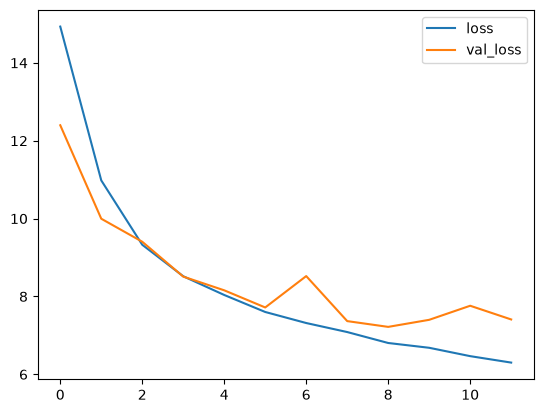

In [56]:
history_df[['loss','val_loss']].plot();

## Age prediction on test

In [57]:
age_pred=  model_age.predict(X_test)

149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


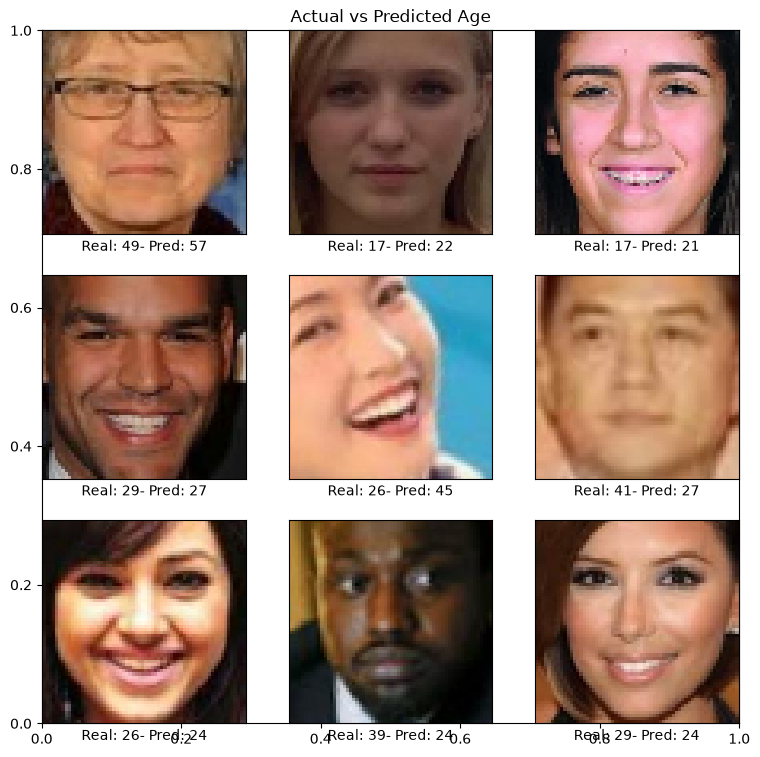

In [69]:
# fig_fashion
fig_age = plt.figure(figsize=(9, 9))
plt.title("Actual vs Predicted Age")
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_test[i])
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.xlabel("Real: "+ str(y_test['age'].iloc[i])+
              "- Pred: "+ str(round(age_pred[i][0])))
plt.show()

# Depoly Age Prediction 

In [75]:
import gradio as gr
from PIL import Image
#prediction function 
def predict_age(img):
    img = Image.fromarray(img).convert("RGB").resize((64,64)) 
    img = np.array(img)/ 255.0 
    img = np.expand_dims(img,axis=0)
    pred= model_age.predict(img, verbose=0)[0][0]
    return round(float(pred))

#app interface
app = gr.Interface(
    fn=predict_age,
    inputs=gr.Image(sources=["upload", "webcam"], type="numpy"),
    outputs=gr.Number(label="Predicted Age"),
    title="Age Predection App 👵👶👦",
    description="Please upload or take an image via web cam!"
)

app.launch(inline=True)


* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.


In [77]:
model_age.save("age_model.keras")
